# Milestone 3 - Pretrained ResNet34 U-Net

What this run changes compared with the scratch model, and why:

| Change | Reason |
|---|---|
| ResNet34 encoder with ImageNet weights | the encoder already knows edges, textures and shapes; with only 313 to 4,100 images per class this usually gives much better masks than learning everything from zero |
| first convolution adapted to 1 gray channel (RGB filters summed) | keeps the pretrained filters useful for gray input |
| classification head on the deepest features (4 "is this defect present" outputs) | the scratch model could not separate real defects from empty pairs well (AUC 0.72 for defects a and b); a dedicated image-level output is trained for exactly that and can later be used as the gate |
| mixed precision (AMP) | faster epochs and less memory |
| warm-up + cosine learning-rate schedule, gradient clipping | stable fine-tuning of a pretrained network, smooth end of training |
| everything else kept | same split, flips + brightness/contrast augmentation, BCE + soft Dice loss, 4 independent sigmoids, native 128 x 800 |

## 0. Setup and settings

In [1]:
import os, glob, math, random, time
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "(turn the GPU on!)")

IMG_H, IMG_W = 128, 800
CANVAS_PIXELS = IMG_H * IMG_W
DEFECTS = ["defect_a", "defect_b", "defect_c", "defect_d"]
IMG_MEAN, IMG_STD = 0.3314, 0.1892          # training-set statistics (same as the scratch model)

DEBUG = False                         # True: tiny subset and 1 epoch, to test the notebook quickly
CFG = dict(run_name="m3-unet-resnet34-v1", encoder="resnet34", pretrained=True, epochs=1 if DEBUG else 20,
           batch_size=16, lr_decoder=1e-3, lr_encoder=3e-4, weight_decay=1e-4, warmup_epochs=1, min_lr_frac=0.02,
           cls_weight=0.5, dice_eps=1.0, amp=True, clip_norm=5.0, num_workers=4, seed=SEED,
           augment="hflip, vflip, brightness, contrast", loss="BCE + soft Dice (positives) + 0.5 * classification BCE")
print(CFG)

PyTorch 2.11.0+cu128 | device: cuda Tesla T4
{'run_name': 'm3-unet-resnet34-v1', 'encoder': 'resnet34', 'pretrained': True, 'epochs': 20, 'batch_size': 16, 'lr_decoder': 0.001, 'lr_encoder': 0.0003, 'weight_decay': 0.0001, 'warmup_epochs': 1, 'min_lr_frac': 0.02, 'cls_weight': 0.5, 'dice_eps': 1.0, 'amp': True, 'clip_norm': 5.0, 'num_workers': 4, 'seed': 42, 'augment': 'hflip, vflip, brightness, contrast', 'loss': 'BCE + soft Dice (positives) + 0.5 * classification BCE'}


## 1. Files, split and image index

In [2]:
def find_file(name, known=None):
    if known and os.path.exists(known):
        return known
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    if not hits:
        raise FileNotFoundError(f"{name} not found - attach the right input to this notebook")
    return sorted(hits)[0]

TRAIN_CSV = find_file("train.csv", "/kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv")
HOLDOUT_CSV = find_file("holdout.csv", "/kaggle/input/notebooks/mruniksurya/milestone-1/holdout.csv")

long = pd.read_csv(TRAIN_CSV)
rle_table = long.pivot(index="image_id", columns="defect_type", values="mask_rle")[DEFECTS]
hold = pd.read_csv(HOLDOUT_CSV)
is_val = hold["split"].astype(str).str.lower().isin({"val", "valid", "validation", "holdout"})
val_ids = sorted(set(hold.loc[is_val, "image_id"]))
train_ids = sorted(set(rle_table.index) - set(val_ids))
assert len(val_ids) == 2279 and len(train_ids) == 9114, (len(train_ids), len(val_ids))

hits = glob.glob(f"/kaggle/input/**/{train_ids[0]}.*", recursive=True)
IMG_DIR = os.path.dirname(hits[0])
IMAGE_INDEX = {os.path.splitext(f)[0]: os.path.join(IMG_DIR, f) for f in os.listdir(IMG_DIR)}
assert set(train_ids).issubset(IMAGE_INDEX) and set(val_ids).issubset(IMAGE_INDEX)
if DEBUG:
    train_ids, val_ids = train_ids[:64], val_ids[:32]
print("train images:", len(train_ids), "| validation images:", len(val_ids), "| image folder:", IMG_DIR)

train images: 9114 | validation images: 2279 | image folder: /kaggle/input/competitions/industrial-surface-defect-detection/public/train


## 2. RLE decoder and metric

In [3]:
def rle_decode(rle, shape=(IMG_H, IMG_W)):
    flat = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    if isinstance(rle, str) and rle.strip():
        tok = [int(t) for t in rle.split()]
        starts = np.array(tok[0::2]) - 1
        ends = starts + np.array(tok[1::2])
        for s, e in zip(starts, ends):
            flat[max(s, 0):min(e, flat.size)] = 1
    return flat.reshape(shape, order="F")

def dice_empty_aware(inter, pred_area, gt_area):
    inter, pred_area, gt_area = (np.asarray(a, dtype=np.float64) for a in (inter, pred_area, gt_area))
    denom = pred_area + gt_area
    dice = np.where(denom > 0, 2 * inter / np.maximum(denom, 1), 0.0)
    return np.where((pred_area == 0) & (gt_area == 0), 1.0, dice)

def competition_score(inter, pred_area, gt_area, canvas=CANVAS_PIXELS, weights=(0.70, 0.20, 0.10)):
    inter, pred_area, gt_area = (np.asarray(a, dtype=np.float64) for a in (inter, pred_area, gt_area))
    positive = gt_area > 0
    empty = ~positive
    dice = dice_empty_aware(inter, pred_area, gt_area)
    fg = dice[positive].mean()
    fp = 1 - (pred_area[empty] / canvas).mean()
    ea = (pred_area[empty] == 0).mean()
    return {"foreground_dice": fg, "false_positive_score": fp, "empty_accuracy": ea,
            "score": weights[0] * fg + weights[1] * fp + weights[2] * ea}

def both_scores(inter, pred_area, gt_area):
    """A = area-based reading (helper formula). B = per-pair reading 0.7*FG Dice + 0.3*empty accuracy.
    On the leaderboard B tracked the real scores much better than A."""
    m = competition_score(np.ravel(inter), np.ravel(pred_area), np.ravel(gt_area))
    return dict(A=m["score"], B=0.7 * m["foreground_dice"] + 0.3 * m["empty_accuracy"],
                fg=m["foreground_dice"], ea=m["empty_accuracy"])

def auc_score(score, label):
    """P(random positive pair scores higher than random empty pair); ties count half."""
    score, label = np.asarray(score, dtype=np.float64), np.asarray(label, dtype=bool)
    order = np.argsort(score, kind="mergesort")
    _, inv, counts = np.unique(score[order], return_inverse=True, return_counts=True)
    ranks = np.empty(len(score)); ranks[order] = (np.cumsum(counts) - (counts - 1) / 2.0)[inv]
    n1, n0 = label.sum(), (~label).sum()
    return float((ranks[label].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))

## 3. Dataset
One sample = one image: `(1,128,800)` normalised float32 image and `(4,128,800)` float32 masks. Flips hit image and masks together; brightness and contrast change only the image. The image-level "is defect k present" labels are computed from the masks inside the training loop.

In [4]:
def augment_pair(img, masks):
    if random.random() < 0.5:
        img, masks = img[:, ::-1], masks[:, :, ::-1]          # horizontal flip
    if random.random() < 0.5:
        img, masks = img[::-1, :], masks[:, ::-1, :]          # vertical flip
    img = np.clip(img * random.uniform(0.8, 1.2) + random.uniform(-0.1, 0.1), 0.0, 1.0)
    return img, masks

class SurfaceDataset(Dataset):
    def __init__(self, image_ids, augment=False):
        self.ids = list(image_ids)
        self.rows = rle_table.loc[self.ids, DEFECTS].values
        self.augment = augment
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, i):
        img = cv2.imread(IMAGE_INDEX[self.ids[i]], cv2.IMREAD_GRAYSCALE)
        assert img is not None and img.shape == (IMG_H, IMG_W)
        img = img.astype(np.float32) / 255.0
        masks = np.stack([rle_decode(r) for r in self.rows[i]]).astype(np.float32)
        if self.augment:
            img, masks = augment_pair(img, masks)
        img = (img - IMG_MEAN) / IMG_STD
        return (torch.from_numpy(np.ascontiguousarray(img))[None].float(), torch.from_numpy(np.ascontiguousarray(masks)))

train_ds, val_ds = SurfaceDataset(train_ids, augment=True), SurfaceDataset(val_ids, augment=False)
kw = dict(num_workers=CFG["num_workers"], pin_memory=True, persistent_workers=CFG["num_workers"] > 0)
train_loader = DataLoader(train_ds, batch_size=CFG["batch_size"], shuffle=True, drop_last=True, **kw)
val_loader = DataLoader(val_ds, batch_size=CFG["batch_size"], shuffle=False, **kw)
x, y = next(iter(train_loader))
print("image batch:", tuple(x.shape), x.dtype, "| mask batch:", tuple(y.shape), y.dtype, "| batches per epoch:", len(train_loader))

image batch: (16, 1, 128, 800) torch.float32 | mask batch: (16, 4, 128, 800) torch.float32 | batches per epoch: 569


## 4. Model: ResNet34 encoder + U-Net decoder (+ classification head)
**Transfer learning.** ResNet34 was trained on ImageNet photographs. Its early layers detect edges and textures, its deeper layers combine them into shapes. Surface defects are textures and edges too, so these filters are a far better starting point than random numbers. We keep them and fine-tune everything with a smaller learning rate for the encoder (it only needs adjusting) than for the decoder (it starts random).

**Grayscale adaptation.** ResNet's first convolution expects 3 channels. We build a 1-channel convolution whose filters are the sum of the three RGB filters. For a gray image (R = G = B) this gives exactly the same output as the original network.

**Encoder-decoder shapes** for a 128 x 800 input (each stage halves the size):

| stage | channels | size |
|---|---|---|
| stem (conv 7x7, stride 2) | 64 | 64 x 400 |
| layer1 (after max-pool) | 64 | 32 x 200 |
| layer2 | 128 | 16 x 100 |
| layer3 | 256 | 8 x 50 |
| layer4 | 512 | 4 x 25 |

The decoder upsamples step by step and concatenates the encoder map of the same size (skip connection), as in the scratch U-Net. A final upsampling returns to 128 x 800 and a 1x1 convolution gives 4 logits per pixel.

**Classification head.** Global average pooling of the layer4 features, then a linear layer with 4 outputs: "is defect k present in this image?". It is trained with its own BCE loss. This is the image-level detector we lacked.

In [5]:
from torchvision.models import resnet34
try:
    from torchvision.models import ResNet34_Weights
    _weights = ResNet34_Weights.IMAGENET1K_V1 if CFG["pretrained"] else None
    _base = resnet34(weights=_weights)
except ImportError:                                          
    _base = resnet34(pretrained=CFG["pretrained"])

class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))
    def forward(self, x):
        return self.block(x)

class UpBlock(nn.Module):
    """Upsample to the skip's size, concatenate, DoubleConv."""
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.conv = DoubleConv(in_ch + skip_ch, out_ch)
    def forward(self, x, skip):
        x = F.interpolate(x, size=skip.shape[-2:], mode="nearest")
        return self.conv(torch.cat([x, skip], dim=1))

class ResNetUNet(nn.Module):
    """ResNet34 encoder (1 gray input channel) + U-Net decoder + image-level classification head.
    forward(x) -> (segmentation logits (B,4,H,W), classification logits (B,4))."""
    def __init__(self, base, n_classes=4):
        super().__init__()
        w = base.conv1.weight.data.sum(dim=1, keepdim=True)              # (64,1,7,7): RGB filters summed
        conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
        conv1.weight.data.copy_(w)
        self.stem = nn.Sequential(conv1, base.bn1, base.relu)              # 64 ch, 1/2
        self.pool = base.maxpool                                           # 1/4
        self.layer1, self.layer2, self.layer3, self.layer4 = base.layer1, base.layer2, base.layer3, base.layer4
        self.up3 = UpBlock(512, 256, 256)
        self.up2 = UpBlock(256, 128, 128)
        self.up1 = UpBlock(128, 64, 64)
        self.up0 = UpBlock(64, 64, 32)
        self.final = DoubleConv(32, 16)
        self.head = nn.Conv2d(16, n_classes, kernel_size=1)
        self.cls_head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.2), nn.Linear(512, n_classes))

    def encoder_parameters(self):
        mods = [self.stem, self.layer1, self.layer2, self.layer3, self.layer4]
        return [p for m in mods for p in m.parameters()]

    def forward(self, x):
        e0 = self.stem(x)                       # (B, 64, 64, 400)
        e1 = self.layer1(self.pool(e0))         # (B, 64, 32, 200)
        e2 = self.layer2(e1)                    # (B,128, 16, 100)
        e3 = self.layer3(e2)                    # (B,256,  8,  50)
        e4 = self.layer4(e3)                    # (B,512,  4,  25)
        d = self.up3(e4, e3)
        d = self.up2(d, e2)
        d = self.up1(d, e1)
        d = self.up0(d, e0)                     # (B, 32, 64, 400)
        d = F.interpolate(d, size=x.shape[-2:], mode="bilinear", align_corners=False)
        seg = self.head(self.final(d))          # (B, 4, 128, 800)
        return seg, self.cls_head(e4)

model = ResNetUNet(_base).to(DEVICE)
enc_ids = {id(p) for p in model.encoder_parameters()}
dec_params = [p for p in model.parameters() if id(p) not in enc_ids]
print(f"parameters: {sum(p.numel() for p in model.parameters()):,} (encoder {sum(p.numel() for p in model.encoder_parameters()):,})")

# shape check before any training
with torch.no_grad():
    model.eval()
    seg, cls = model(torch.randn(2, 1, IMG_H, IMG_W, device=DEVICE))
print("segmentation logits:", tuple(seg.shape), "| classification logits:", tuple(cls.shape))
assert seg.shape == (2, 4, IMG_H, IMG_W) and cls.shape == (2, 4)

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 195MB/s]


parameters: 24,432,072 (encoder 21,278,400)
segmentation logits: (2, 4, 128, 800) | classification logits: (2, 4)


## 5. Loss, evaluation, optimiser and schedule
- **Loss** = BCE over all pixels + soft Dice on positive pairs (as before) + 0.5 x BCE of the classification head against the image-level labels.
- **Evaluation** after each epoch: validation loss; scores under readings A and B at threshold 0.5; the same scores when the classification head acts as a gate (a pair is emptied if its presence probability is below 0.5); and the AUC of the classification head per class. If the gated score is clearly better than the raw one, the classification head is doing its job.
- **Optimiser:** AdamW with two learning rates (decoder 1e-3, encoder 3e-4). **Schedule:** linear warm-up for one epoch, then cosine decay to 2% of the base rate, updated every batch. **AMP:** the forward pass runs in float16, the loss in float32; gradients are scaled to avoid underflow and clipped.

In [6]:
def dice_loss_on_positives(logits, targets, eps):
    probs = torch.sigmoid(logits)
    inter = (probs * targets).sum((2, 3))
    denom = probs.sum((2, 3)) + targets.sum((2, 3))
    dice = (2 * inter + eps) / (denom + eps)
    pos = targets.sum((2, 3)) > 0
    return (1 - dice[pos]).mean() if pos.any() else logits.sum() * 0.0

def loss_fn(seg, cls, y, pres):
    seg_loss = F.binary_cross_entropy_with_logits(seg, y) + dice_loss_on_positives(seg, y, CFG["dice_eps"])
    return seg_loss + CFG["cls_weight"] * F.binary_cross_entropy_with_logits(cls, pres)

USE_AMP = CFG["amp"] and DEVICE.type == "cuda"
def autocast():
    return torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP)

@torch.no_grad()
def evaluate(model, loader, taus=(0.5,)):
    model.eval()
    loss_sum, n = 0.0, 0
    I, PA, G, CP = {t: [] for t in taus}, {t: [] for t in taus}, [], []
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        pres = (y.sum((2, 3)) > 0).float()
        with autocast():
            seg, cls = model(x)
        seg, cls = seg.float(), cls.float()
        loss_sum += loss_fn(seg, cls, y, pres).item() * x.size(0); n += x.size(0)
        probs, gt = torch.sigmoid(seg), y > 0.5
        G.append(gt.sum((2, 3)).cpu().numpy()); CP.append(torch.sigmoid(cls).cpu().numpy())
        for t in taus:
            pred = probs > t
            I[t].append((pred & gt).sum((2, 3)).cpu().numpy()); PA[t].append(pred.sum((2, 3)).cpu().numpy())
    return dict(loss=loss_sum / n, gt=np.concatenate(G), cls=np.concatenate(CP),
                inter={t: np.concatenate(I[t]) for t in taus}, pa={t: np.concatenate(PA[t]) for t in taus})

def summarize(res, tau=0.5, cls_gate=0.5):
    it, pa, gt = res["inter"][tau], res["pa"][tau], res["gt"]
    raw = both_scores(it, pa, gt)
    keep = res["cls"] >= cls_gate
    gated = both_scores(np.where(keep, it, 0), np.where(keep, pa, 0), gt)
    aucs = [auc_score(res["cls"][:, k], gt[:, k] > 0) for k in range(4)]
    return raw, gated, aucs

opt = torch.optim.AdamW([dict(params=model.encoder_parameters(), lr=CFG["lr_encoder"]),
                         dict(params=dec_params, lr=CFG["lr_decoder"])], weight_decay=CFG["weight_decay"])
steps_per_epoch = len(train_loader)
total_steps, warm_steps = CFG["epochs"] * steps_per_epoch, max(1, CFG["warmup_epochs"] * steps_per_epoch)
def lr_lambda(step):
    if step < warm_steps:
        return (step + 1) / warm_steps
    progress = (step - warm_steps) / max(1, total_steps - warm_steps)
    return CFG["min_lr_frac"] + (1 - CFG["min_lr_frac"]) * 0.5 * (1 + math.cos(math.pi * progress))
sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
try:
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
except Exception:
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
print("steps per epoch:", steps_per_epoch, "| total steps:", total_steps, "| AMP:", USE_AMP)

steps per epoch: 569 | total steps: 11380 | AMP: True


## 6. Weights & Biases run

In [7]:
import wandb
from kaggle_secrets import UserSecretsClient
wandb.login(key=UserSecretsClient().get_secret("WANDB_API_KEY"))
run = wandb.init(entity="22f2001613-indian-institute-of-technology-madras", project="22f2001613-t32026",
                 name=CFG["run_name"], config=dict(CFG, n_train=len(train_ids), n_val=len(val_ids)),
                 tags=["milestone-3", "pretrained", "resnet34"])

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: 22f2001613 (22f2001613-indian-institute-of-technology-madras) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261027_022150-jxgsnsq1
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run m3-unet-resnet34-v1
wandb: ⭐️ View project at https://wandb.ai/22f2001613-indian-institute-of-technology-madras/22f2001613-t32026
wandb: 🚀 View run at https://wandb.ai/22f2001613-indian-institute-of-technology-madras/22f2

## 7. Train
Per epoch: train loss, validation loss, scores A and B (raw and classification-gated), classification AUC, learning rates and time. Two checkpoints are saved: `best_r34.pt` (best average of raw A and B at threshold 0.5) and `last_r34.pt` (final weights). **Check the time of epoch 1:** if it is much above 4 minutes, tell me before waiting for all 20 epochs.

In [8]:
history, best_obj = [], -1.0
for epoch in range(1, CFG["epochs"] + 1):
    t0 = time.time()
    model.train()
    run_loss, n = 0.0, 0
    for x, y in train_loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        pres = (y.sum((2, 3)) > 0).float()
        opt.zero_grad(set_to_none=True)
        with autocast():
            seg, cls = model(x)
        loss = loss_fn(seg.float(), cls.float(), y, pres)             # loss in float32
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["clip_norm"])
        scaler.step(opt); scaler.update(); sched.step()
        run_loss += loss.item() * x.size(0); n += x.size(0)
    train_loss = run_loss / n

    res = evaluate(model, val_loader)
    raw, gated, aucs = summarize(res)
    row = dict(epoch=epoch, train_loss=train_loss, val_loss=res["loss"], A=raw["A"], B=raw["B"], fg=raw["fg"], ea=raw["ea"],
               A_gate=gated["A"], B_gate=gated["B"], cls_auc=float(np.mean(aucs)), time_s=time.time() - t0)
    history.append(row)
    wandb.log({"epoch": epoch, "train/loss": train_loss, "val/loss": res["loss"], "val/A@0.5": raw["A"], "val/B@0.5": raw["B"],
               "val/fg_dice@0.5": raw["fg"], "val/empty_acc@0.5": raw["ea"], "val/A_clsgate": gated["A"], "val/B_clsgate": gated["B"],
               "val/cls_auc_mean": row["cls_auc"], "lr_decoder": opt.param_groups[1]["lr"], "lr_encoder": opt.param_groups[0]["lr"],
               "epoch_time_s": row["time_s"]})
    print(f"epoch {epoch:02d} | train {train_loss:.4f} | val {res['loss']:.4f} | A {raw['A']:.4f} B {raw['B']:.4f} fg {raw['fg']:.4f} ea {raw['ea']:.3f} | "
          f"cls-gated A {gated['A']:.4f} B {gated['B']:.4f} | cls AUC {row['cls_auc']:.3f} | {row['time_s']:.0f}s")
    obj = 0.5 * (raw["A"] + raw["B"])
    if obj > best_obj:
        best_obj = obj
        torch.save(model.state_dict(), "/kaggle/working/best_r34.pt")
torch.save(model.state_dict(), "/kaggle/working/last_r34.pt")

epoch 01 | train 1.3584 | val 1.0102 | A 0.5173 B 0.4764 fg 0.3450 ea 0.783 | cls-gated A 0.5003 B 0.4901 | cls AUC 0.873 | 124s
epoch 02 | train 0.8176 | val 0.7119 | A 0.5880 B 0.5002 fg 0.4795 ea 0.549 | cls-gated A 0.5071 B 0.5030 | cls AUC 0.891 | 124s
epoch 03 | train 0.6980 | val 0.6532 | A 0.6087 B 0.5032 fg 0.5185 ea 0.468 | cls-gated A 0.5431 B 0.5394 | cls AUC 0.894 | 125s
epoch 04 | train 0.6554 | val 0.6072 | A 0.6268 B 0.5194 fg 0.5458 ea 0.458 | cls-gated A 0.5896 B 0.5841 | cls AUC 0.900 | 125s
epoch 05 | train 0.6225 | val 0.5783 | A 0.6467 B 0.5571 fg 0.5612 ea 0.547 | cls-gated A 0.5917 B 0.5879 | cls AUC 0.924 | 125s
epoch 06 | train 0.5934 | val 0.5562 | A 0.6522 B 0.5588 fg 0.5718 ea 0.528 | cls-gated A 0.6156 B 0.6119 | cls AUC 0.935 | 125s
epoch 07 | train 0.5760 | val 0.5932 | A 0.6459 B 0.5576 fg 0.5603 ea 0.551 | cls-gated A 0.5932 B 0.5873 | cls AUC 0.932 | 125s
epoch 08 | train 0.5572 | val 0.5278 | A 0.6761 B 0.6028 fg 0.5909 ea 0.631 | cls-gated A 0.6361 

## 8. Results
Reference (scratch model, epoch 14, threshold 0.5, raw): A 0.6020, B 0.4800, foreground Dice 0.5233, loss 0.5311 (different loss definition, not directly comparable).

       train_loss  val_loss       A       B      fg      ea  A_gate  B_gate  cls_auc    time_s
epoch                                                                                         
1          1.3584    1.0102  0.5173  0.4764  0.3450  0.7829  0.5003  0.4901   0.8731  124.0390
2          0.8176    0.7119  0.5880  0.5002  0.4795  0.5485  0.5071  0.5030   0.8908  124.2550
3          0.6980    0.6532  0.6087  0.5032  0.5185  0.4676  0.5431  0.5394   0.8944  124.8578
4          0.6554    0.6072  0.6268  0.5194  0.5458  0.4579  0.5896  0.5841   0.9001  124.7533
5          0.6225    0.5783  0.6467  0.5571  0.5612  0.5474  0.5917  0.5879   0.9238  124.7463
6          0.5934    0.5562  0.6522  0.5588  0.5718  0.5285  0.6156  0.6119   0.9348  124.7883
7          0.5760    0.5932  0.6459  0.5576  0.5603  0.5511  0.5932  0.5873   0.9321  124.6021
8          0.5572    0.5278  0.6761  0.6028  0.5909  0.6307  0.6361  0.6326   0.9460  124.7998
9          0.5335    0.5321  0.6688  0.5737  0.596

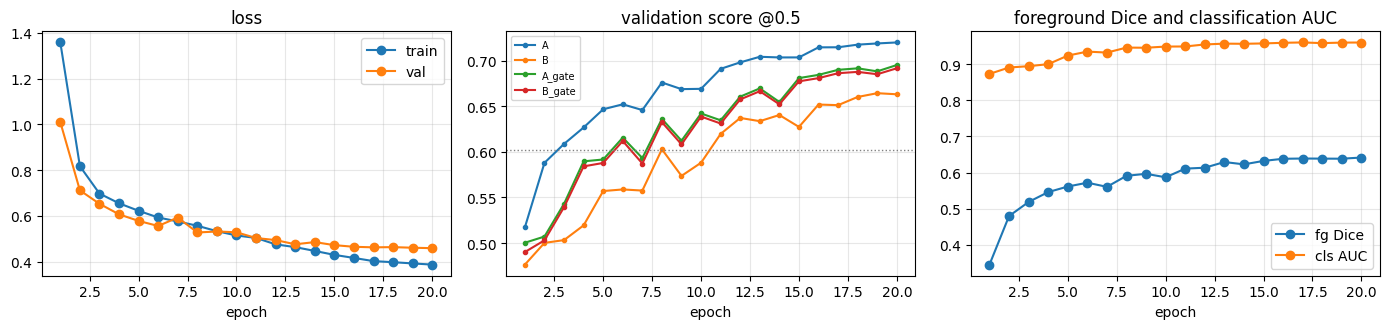

In [9]:
hist = pd.DataFrame(history).set_index("epoch")
print(hist.round(4).to_string())
best_epoch = int((0.5 * (hist["A"] + hist["B"])).idxmax())
print("\nbest epoch (average of raw A and B):", best_epoch)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
axes[0].plot(hist.index, hist["train_loss"], marker="o", label="train"); axes[0].plot(hist.index, hist["val_loss"], marker="o", label="val")
axes[0].set_title("loss"); axes[0].legend(); axes[0].grid(alpha=0.3)
for c in ["A", "B", "A_gate", "B_gate"]: axes[1].plot(hist.index, hist[c], marker=".", label=c)
axes[1].axhline(0.6020, color="gray", ls=":", lw=1); axes[1].set_title("validation score @0.5"); axes[1].legend(fontsize=7); axes[1].grid(alpha=0.3)
axes[2].plot(hist.index, hist["fg"], marker="o", label="fg Dice"); axes[2].plot(hist.index, hist["cls_auc"], marker="o", label="cls AUC")
axes[2].set_title("foreground Dice and classification AUC"); axes[2].legend(); axes[2].grid(alpha=0.3)
for a in axes: a.set_xlabel("epoch")
plt.tight_layout(); plt.savefig("/kaggle/working/m3_r34_curves.png", dpi=120); plt.show()
wandb.log({"curves": wandb.Image("/kaggle/working/m3_r34_curves.png")})
hist.to_csv("/kaggle/working/m3_r34_history.csv")

## 9. Threshold sweep and per-class view with the best checkpoint

In [10]:
model.load_state_dict(torch.load("/kaggle/working/best_r34.pt", map_location=DEVICE))
taus = (0.3, 0.5, 0.7, 0.8, 0.9)
res = evaluate(model, val_loader, taus=taus)
rows = []
for t in taus:
    raw, gated, aucs = summarize(res, tau=t)
    rows.append(dict(tau=t, A=raw["A"], B=raw["B"], fg=raw["fg"], ea=raw["ea"], A_clsgate=gated["A"], B_clsgate=gated["B"]))
print(pd.DataFrame(rows).round(4).to_string(index=False))

gt, pa, it, cp = res["gt"], res["pa"][0.5], res["inter"][0.5], res["cls"]
diag = []
for k, d in enumerate(DEFECTS):
    pos = gt[:, k] > 0
    diag.append(dict(cls=d, true_pos_rate=pos.mean(), pred_pos_rate=(pa[:, k] > 0).mean(), recall_pairs=(it[pos, k] > 0).mean(),
                     fg_dice=dice_empty_aware(it[pos, k], pa[pos, k], gt[pos, k]).mean(), empty_acc=(pa[~pos, k] == 0).mean(),
                     cls_auc=auc_score(cp[:, k], pos)))
print(pd.DataFrame(diag).set_index("cls").round(3).to_string())
wandb.summary.update({"best_epoch": best_epoch, "best_A@0.5": float(hist.loc[best_epoch, "A"]), "best_B@0.5": float(hist.loc[best_epoch, "B"])})
wandb.finish()

wandb: updating run metadata


 tau      A      B     fg     ea  A_clsgate  B_clsgate
 0.3 0.7177 0.6599 0.6389 0.7088     0.6880     0.6848
 0.5 0.7189 0.6644 0.6383 0.7253     0.6883     0.6852
 0.7 0.7196 0.6684 0.6368 0.7420     0.6885     0.6853
 0.8 0.7199 0.6714 0.6352 0.7557     0.6883     0.6851
 0.9 0.7189 0.6740 0.6310 0.7743     0.6874     0.6843
          true_pos_rate  pred_pos_rate  recall_pairs  fg_dice  empty_acc  cls_auc
cls                                                                              
defect_a          0.095          0.359         0.741    0.447      0.693    0.929
defect_b          0.028          0.320         0.825    0.458      0.697    0.965
defect_c          0.360          0.620         0.941    0.655      0.573    0.958
defect_d          0.150          0.222         0.944    0.752      0.907    0.987


wandb: uploading history steps 19-20, summary, console lines 19-55
wandb: 
wandb: Run history:
wandb:            epoch ▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
wandb:     epoch_time_s ▁▃▇▆▆▇▅▇██▅▇▅▄▄▅▅▆▇▆
wandb:       lr_decoder ████▇▇▆▆▅▅▄▄▃▃▂▂▁▁▁▁
wandb:       lr_encoder ████▇▇▆▆▅▅▄▄▃▃▂▂▁▁▁▁
wandb:       train/loss █▄▃▃▃▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁
wandb:        val/A@0.5 ▁▃▄▅▅▆▅▆▆▆▇▇▇▇▇█████
wandb:    val/A_clsgate ▁▁▃▄▄▅▄▆▅▆▆▇▇▇▇█████
wandb:        val/B@0.5 ▁▂▂▃▄▄▄▆▅▅▆▇▇▇▇█████
wandb:    val/B_clsgate ▁▁▃▄▄▅▄▆▅▆▆▇▇▇██████
wandb: val/cls_auc_mean ▁▂▃▃▅▆▆▇▇▇▇█████████
wandb:               +3 ...
wandb: 
wandb: Run summary:
wandb:    best_A@0.5 0.71894
wandb:    best_B@0.5 0.66438
wandb:    best_epoch 19
wandb:         epoch 20
wandb:  epoch_time_s 124.71397
wandb:    lr_decoder 2e-05
wandb:    lr_encoder 1e-05
wandb:    train/loss 0.38741
wandb:     val/A@0.5 0.72004
wandb: val/A_clsgate 0.69526
wandb:            +6 ...
wandb: 
wandb: 🚀 View run m3-unet-resnet34-v1 at: https://wandb.ai/22f2001613-indian-institute-o